# Results processing

Load, summarise, compare, and visualise benchmark results.

In [1]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "06_NOTEBOOKS" else Path.cwd()
MODULES_DIR = REPO_ROOT / "modules"
if str(MODULES_DIR) not in sys.path:
    sys.path.insert(0, str(MODULES_DIR))

from load_results import load_results, save_cache
from xgb_prediction_plots import plot_parity_grid, plot_residual_grid

In [2]:
DATE = "20260923"
OUTPUTS_ROOT = REPO_ROOT / "07_OUTPUTS"
RUN_DIR = OUTPUTS_ROOT / DATE
FIGURES_DIR = RUN_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EMBEDDING_LABELS = {
    "morgan_fps": "ECFP4",
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "molclr": "MolCLR",
    "maceoff_large": "MACE-OFF",
}
MODEL_LABELS = {"linear": "LR", "rf": "RF", "xgboost": "XGB", "mlp": "MLP"}
DATASET_LABELS = {"CD": r"$\rho_{cryst}$"}

EMBEDDING_ORDER = ["ECFP4", "QU", "CheMeleon", "MolCLR", "MACE-OFF"]
MODEL_ORDER = ["LR", "RF", "XGB", "MLP"]
DATASET_ORDER = [r"$\rho_{cryst}$", "HOF", "IS"]
DATASET_UNITS = {
    r"$\rho_{cryst}$": r"Test RMSE (g/cm$^3$)",
    "HOF": "Test RMSE (kJ/mol)",
    "IS": "Test RMSE (log(J))",
}
ALPHA = 0.05

## Load and prepare results

In [3]:
results_df = load_results(OUTPUTS_ROOT, date=DATE)
save_cache(results_df, outputs_root=OUTPUTS_ROOT, date=DATE)
results_df.head()

,date,dataset_from_path,model_from_path,embedding_from_path,split_dir,summary_path,split_method_from_path,split_seed_from_path,dataset,model,...,outdir,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2,train_MSE,test_MSE,run_id
0,20260923,HOF,linear,molclr,split=cluster_label0_modelseed=0,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts_re...,33.141997,43.062028,0.824953,41.650050,56.215136,-0.444463,NaN,NaN,20260923|HOF|linear|molclr|cluster_label0|42|s...
1,20260923,HOF,linear,molclr,split=cluster_label2_modelseed=0,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts_re...,32.420829,42.997071,0.793798,55.759204,76.177252,0.430401,NaN,NaN,20260923|HOF|linear|molclr|cluster_label2|42|s...
2,20260923,HOF,linear,molclr,split=cluster_label1_modelseed=0,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts_re...,35.724425,45.868754,0.828438,29.185118,39.193396,0.490764,NaN,NaN,20260923|HOF|linear|molclr|cluster_label1|42|s...
3,20260923,HOF,linear,hq_descriptor,split=cluster_label0_modelseed=0,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts_re...,28.157010,36.793844,0.872204,28.872614,37.937818,0.342123,NaN,NaN,20260923|HOF|linear|hq_descriptor|cluster_labe...
4,20260923,HOF,linear,hq_descriptor,split=cluster_label2_modelseed=0,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts_re...,25.090502,34.055856,0.870641,34.399838,48.751562,0.766710,NaN,NaN,20260923|HOF|linear|hq_descriptor|cluster_labe...


In [4]:
def prepare_results(results: pd.DataFrame) -> pd.DataFrame:
    """Apply display labels, ordering, and the agreed quality filter."""
    prepared = results.loc[results["test_R2"] > -0.5].copy()
    prepared["embedding"] = prepared["embedding"].replace(EMBEDDING_LABELS)
    prepared["model"] = prepared["model"].replace(MODEL_LABELS)
    prepared["dataset"] = prepared["dataset"].replace(DATASET_LABELS)

    prepared["embedding"] = pd.Categorical(
        prepared["embedding"], categories=EMBEDDING_ORDER, ordered=True
    )
    prepared["model"] = pd.Categorical(
        prepared["model"], categories=MODEL_ORDER, ordered=True
    )
    prepared["dataset"] = pd.Categorical(
        prepared["dataset"], categories=DATASET_ORDER, ordered=True
    )
    return prepared


df = prepare_results(results_df)
result_columns = [
    "dataset", "model", "seed", "split_method", "embedding",
    "test_MAE", "test_RMSE", "test_R2",
]
clean_results = df[result_columns].dropna(subset=["dataset", "model", "embedding"])
clean_results.head()

,dataset,model,seed,split_method,embedding,test_MAE,test_RMSE,test_R2
0,HOF,LR,0,cluster_label0,MolCLR,41.650050,56.215136,-0.444463
1,HOF,LR,0,cluster_label2,MolCLR,55.759204,76.177252,0.430401
2,HOF,LR,0,cluster_label1,MolCLR,29.185118,39.193396,0.490764
3,HOF,LR,0,cluster_label0,QU,28.872614,37.937818,0.342123
4,HOF,LR,0,cluster_label2,QU,34.399838,48.751562,0.766710


## Reusable analysis and plotting helpers

In [5]:
def save_figure(fig: plt.Figure, filename: str) -> Path:
    """Save a figure consistently, then display it in the notebook."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {path.relative_to(REPO_ROOT)}")
    return path


def select_split(results: pd.DataFrame, split_name: str) -> pd.DataFrame:
    mask = results["split_method"].str.contains(split_name, case=False, na=False)
    return results.loc[mask].copy()


def summarise_results(results: pd.DataFrame) -> pd.DataFrame:
    return (
        results.groupby(["dataset", "embedding"], observed=True)
        [["test_RMSE", "test_R2"]]
        .agg(["mean", "std"])
        .round(3)
    )

In [6]:
def plot_benchmark_rmse(results: pd.DataFrame, filename: str) -> plt.Figure:
    """Plot test RMSE by prediction head and embedding for each dataset."""
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    palette = sns.color_palette("tab10", n_colors=len(EMBEDDING_ORDER))
    fig, axes = plt.subplots(len(DATASET_ORDER), 1, figsize=(14, 14), dpi=300)

    pretrained = {"CheMeleon", "MolCLR", "MACE-OFF"}
    first_pretrained = min(EMBEDDING_ORDER.index(name) for name in pretrained)
    last_pretrained = max(EMBEDDING_ORDER.index(name) for name in pretrained)
    group_width = 0.8
    bar_width = group_width / len(EMBEDDING_ORDER)
    legend_handles = legend_labels = None

    for ax, dataset in zip(axes, DATASET_ORDER):
        subset = results.loc[results["dataset"] == dataset]
        sns.barplot(
            data=subset,
            x="model",
            y="test_RMSE",
            hue="embedding",
            hue_order=EMBEDDING_ORDER,
            palette=palette,
            errorbar="sd",
            gap=0.1,
            ax=ax,
        )

        for x_position in ax.get_xticks():
            left = x_position - group_width / 2 + first_pretrained * bar_width
            right = x_position - group_width / 2 + (last_pretrained + 1) * bar_width
            ax.axvspan(left, right, color="lightgray", alpha=0.2, zorder=0)

        for patch in ax.patches:
            patch.set_zorder(2)

        ax.set(title=str(dataset), xlabel="", ylabel=DATASET_UNITS[dataset])
        ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
        sns.despine(ax=ax)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    legend_handles.append(Patch(facecolor="lightgray", alpha=0.5))
    legend_labels.append("Pre-trained embeddings")
    fig.legend(
        legend_handles,
        legend_labels,
        title="Embedding",
        loc="center left",
        bbox_to_anchor=(0.84, 0.5),
        frameon=False,
    )
    fig.tight_layout(rect=[0, 0, 0.88, 1])
    save_figure(fig, filename)
    return fig

In [7]:
def aggregate_paired_runs(results: pd.DataFrame) -> pd.DataFrame:
    """Average over prediction heads while retaining paired experimental runs."""
    return (
        results.loc[results["embedding"].isin(EMBEDDING_ORDER)]
        .groupby(
            ["dataset", "embedding", "seed", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .mean()
    )


def compare_to_reference(
    results: pd.DataFrame,
    reference: str = "QU",
    candidates: tuple[str, ...] = ("ECFP4", "CheMeleon", "MolCLR", "MACE-OFF"),
) -> pd.DataFrame:
    """Test whether a reference embedding has lower RMSE than each candidate."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        reference_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == reference,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "reference_RMSE"})
        )
        for candidate in candidates:
            candidate_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == candidate,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "candidate_RMSE"})
            )
            paired = reference_scores.merge(
                candidate_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {candidate=}")

            test = ttest_rel(
                paired["reference_RMSE"], paired["candidate_RMSE"], alternative="less"
            )
            records.append({
                "Dataset": dataset,
                "Reference": reference,
                "Candidate": candidate,
                "Paired runs": len(paired),
                "Reference mean RMSE": paired["reference_RMSE"].mean(),
                "Candidate mean RMSE": paired["candidate_RMSE"].mean(),
                "t statistic": test.statistic,
                "p value": test.pvalue,
                "Result": (
                    "Reference significantly better"
                    if test.pvalue < ALPHA
                    else "Candidate equal or better"
                ),
            })

    return pd.DataFrame(records).set_index(["Dataset", "Reference", "Candidate"])

In [8]:
def compare_to_best(results: pd.DataFrame) -> pd.DataFrame:
    """Compare every embedding with the lowest-mean embedding per dataset."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        means = dataset_scores.groupby("embedding", observed=True)["test_RMSE"].mean().sort_values()
        best_embedding = means.index[0]
        best_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == best_embedding,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "best_RMSE"})
        )
        dataset_records = []

        for embedding in means.index[1:]:
            other_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == embedding,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "other_RMSE"})
            )
            paired = best_scores.merge(
                other_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {embedding=}")

            test = ttest_rel(paired["best_RMSE"], paired["other_RMSE"], alternative="less")
            dataset_records.append({
                "Dataset": dataset,
                "Best embedding": best_embedding,
                "Compared embedding": embedding,
                "Paired runs": len(paired),
                "Best mean RMSE": paired["best_RMSE"].mean(),
                "Other mean RMSE": paired["other_RMSE"].mean(),
                "RMSE difference": (paired["other_RMSE"] - paired["best_RMSE"]).mean(),
                "t statistic": test.statistic,
                "Raw p value": test.pvalue,
            })

        if dataset_records:
            reject, adjusted_p, _, _ = multipletests(
                [record["Raw p value"] for record in dataset_records],
                alpha=ALPHA,
                method="holm",
            )
            for record, is_worse, p_value in zip(dataset_records, reject, adjusted_p):
                record["Holm-adjusted p value"] = p_value
                record["Result"] = (
                    "Significantly worse than best"
                    if is_worse
                    else "Not significantly worse than best"
                )
            records.extend(dataset_records)

    return pd.DataFrame(records).set_index(
        ["Dataset", "Best embedding", "Compared embedding"]
    )

In [9]:
def rank_embeddings(results: pd.DataFrame) -> pd.DataFrame:
    """Count dataset/model wins and calculate mean embedding rank."""
    seed_means = (
        results.groupby(["dataset", "model", "embedding"], as_index=False, observed=True)
        ["test_RMSE"]
        .mean()
    )
    seed_means["rank"] = seed_means.groupby(["dataset", "model"], observed=True)[
        "test_RMSE"
    ].rank(method="average", ascending=True)
    seed_means["win"] = seed_means["rank"].eq(1)

    return (
        seed_means.groupby("embedding", observed=True)
        .agg(**{"Win Count": ("win", "sum"), "Avg Rank": ("rank", "mean")})
        .sort_values(["Win Count", "Avg Rank"], ascending=[False, True])
        .round(2)
    )

## Random splits

Empty DataFrame
Columns: [(test_RMSE, mean), (test_RMSE, std), (test_R2, mean), (test_R2, std)]
Index: []

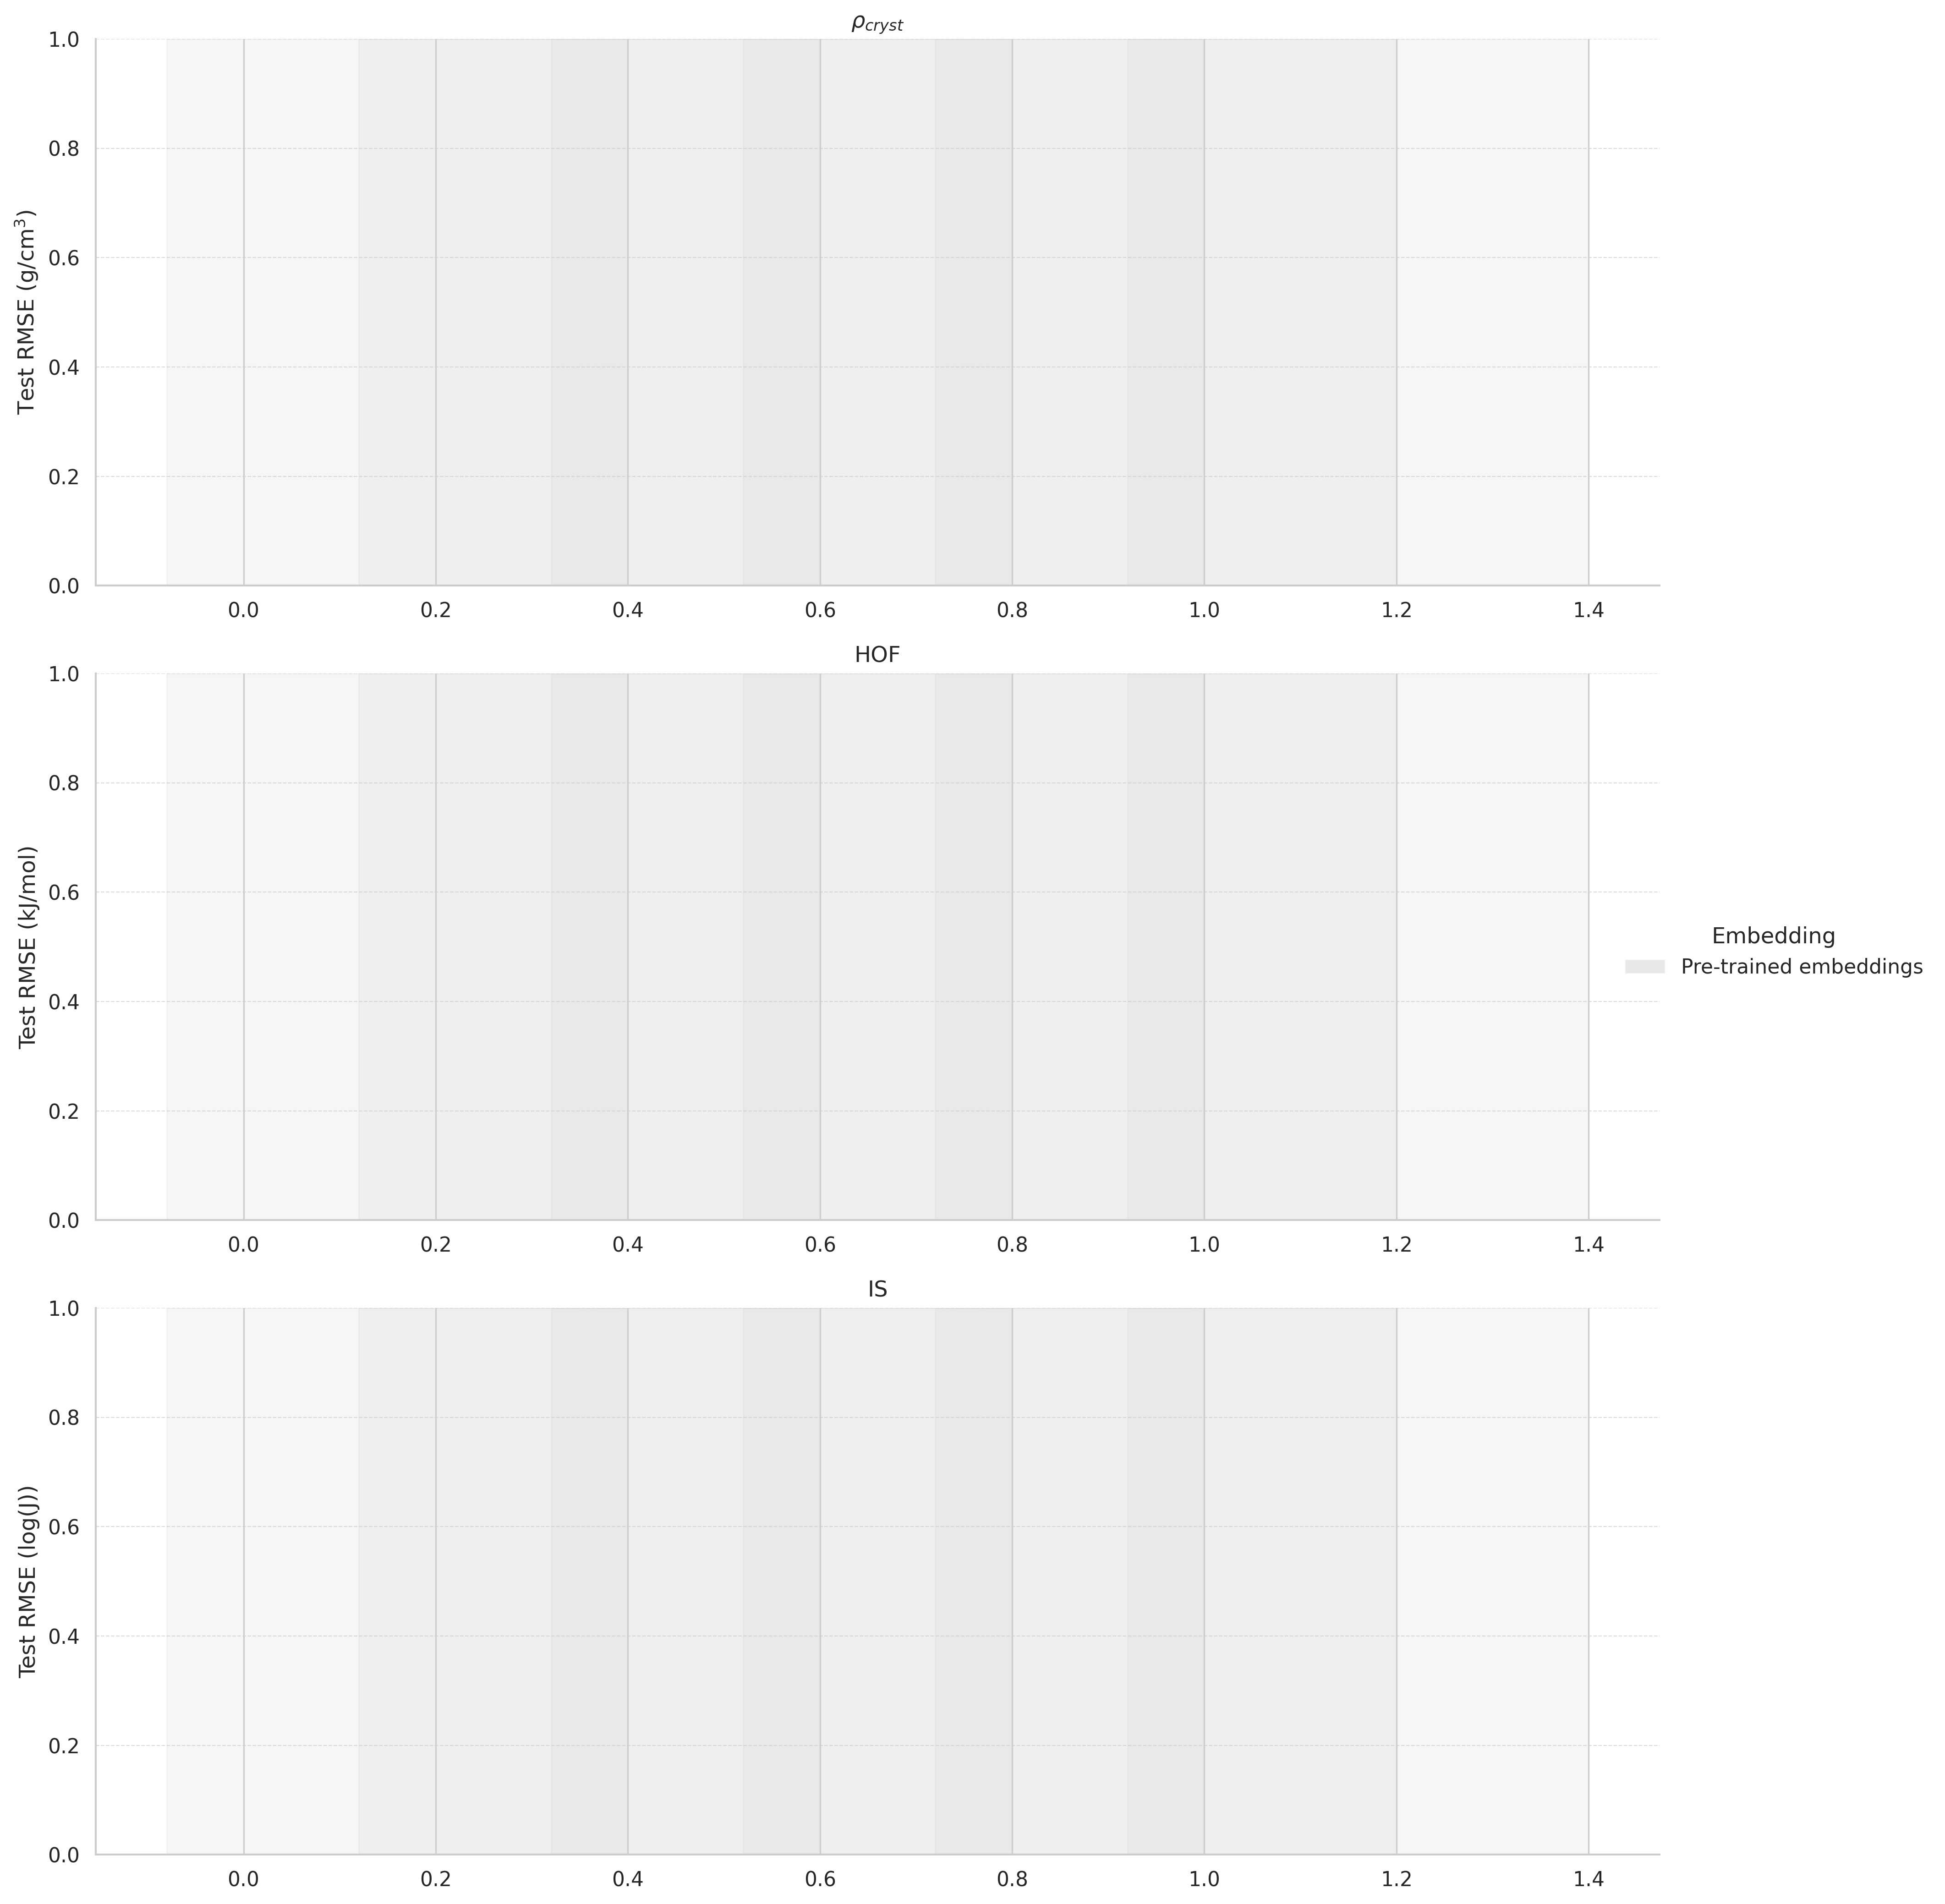

Saved 07_OUTPUTS/20260923/figures/random_split_benchmark_rmse.png


In [10]:
random_results = select_split(clean_results, "random")
display(summarise_results(random_results))
plot_benchmark_rmse(random_results, "random_split_benchmark_rmse.png");

In [11]:
random_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)

/tmp/ipykernel_57513/321736336.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  random_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)


test_RMSE     test_R2    
                                    mean std    mean std
dataset        model embedding                          
$\rho_{cryst}$ LR    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               RF    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               XGB   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               MLP   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
HOF            LR    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               RF    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               XGB   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               MLP   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
IS             LR    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               RF    ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               XGB   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN
               MLP   ECFP4           NaN NaN     NaN NaN
                     QU              NaN NaN     NaN NaN
                     CheMeleon       NaN NaN     NaN NaN
                     MolCLR          NaN NaN     NaN NaN
                     MACE-OFF        NaN NaN     NaN NaN

### Are the foundation-model embeddings equal to or better than QU?

One-sided paired t-tests use matched seed/split runs after averaging across prediction heads. Lower RMSE is better.

In [12]:
display(compare_to_reference(random_results).round(3))

KeyError: "None of ['Dataset', 'Reference', 'Candidate'] are in the columns"

### Comparisons with the best embedding

Each embedding is compared with the lowest-mean embedding for its dataset. Holm correction is applied within each dataset.

In [ ]:
display(compare_to_best(random_results).round(3))
display(rank_embeddings(random_results))

KeyError: "None of ['Dataset', 'Best embedding', 'Compared embedding'] are in the columns"

## Cluster splits

test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.184   0.022   0.152  0.211
               QU            0.139   0.050   0.400  0.117
               CheMeleon     0.165   0.004   0.326  0.035
               MolCLR        0.133   0.079   0.386  0.304
               MACE-OFF      0.116   0.074   0.536  0.279
HOF            ECFP4        48.018   3.634   0.073  0.343
               QU           43.209   3.985   0.209  0.135
               CheMeleon    35.992  11.904   0.443  0.304
               MolCLR       49.792   6.110  -0.063  0.402
               MACE-OFF     46.499   6.388   0.127  0.187
IS             ECFP4         1.114   0.059   0.035  0.103
               QU            0.991   0.026   0.238  0.039
               CheMeleon     1.019   0.002   0.195  0.003
               MolCLR        1.049   0.019   0.147  0.031
               MACE-OFF      0.944   0.061   0.307  0.090

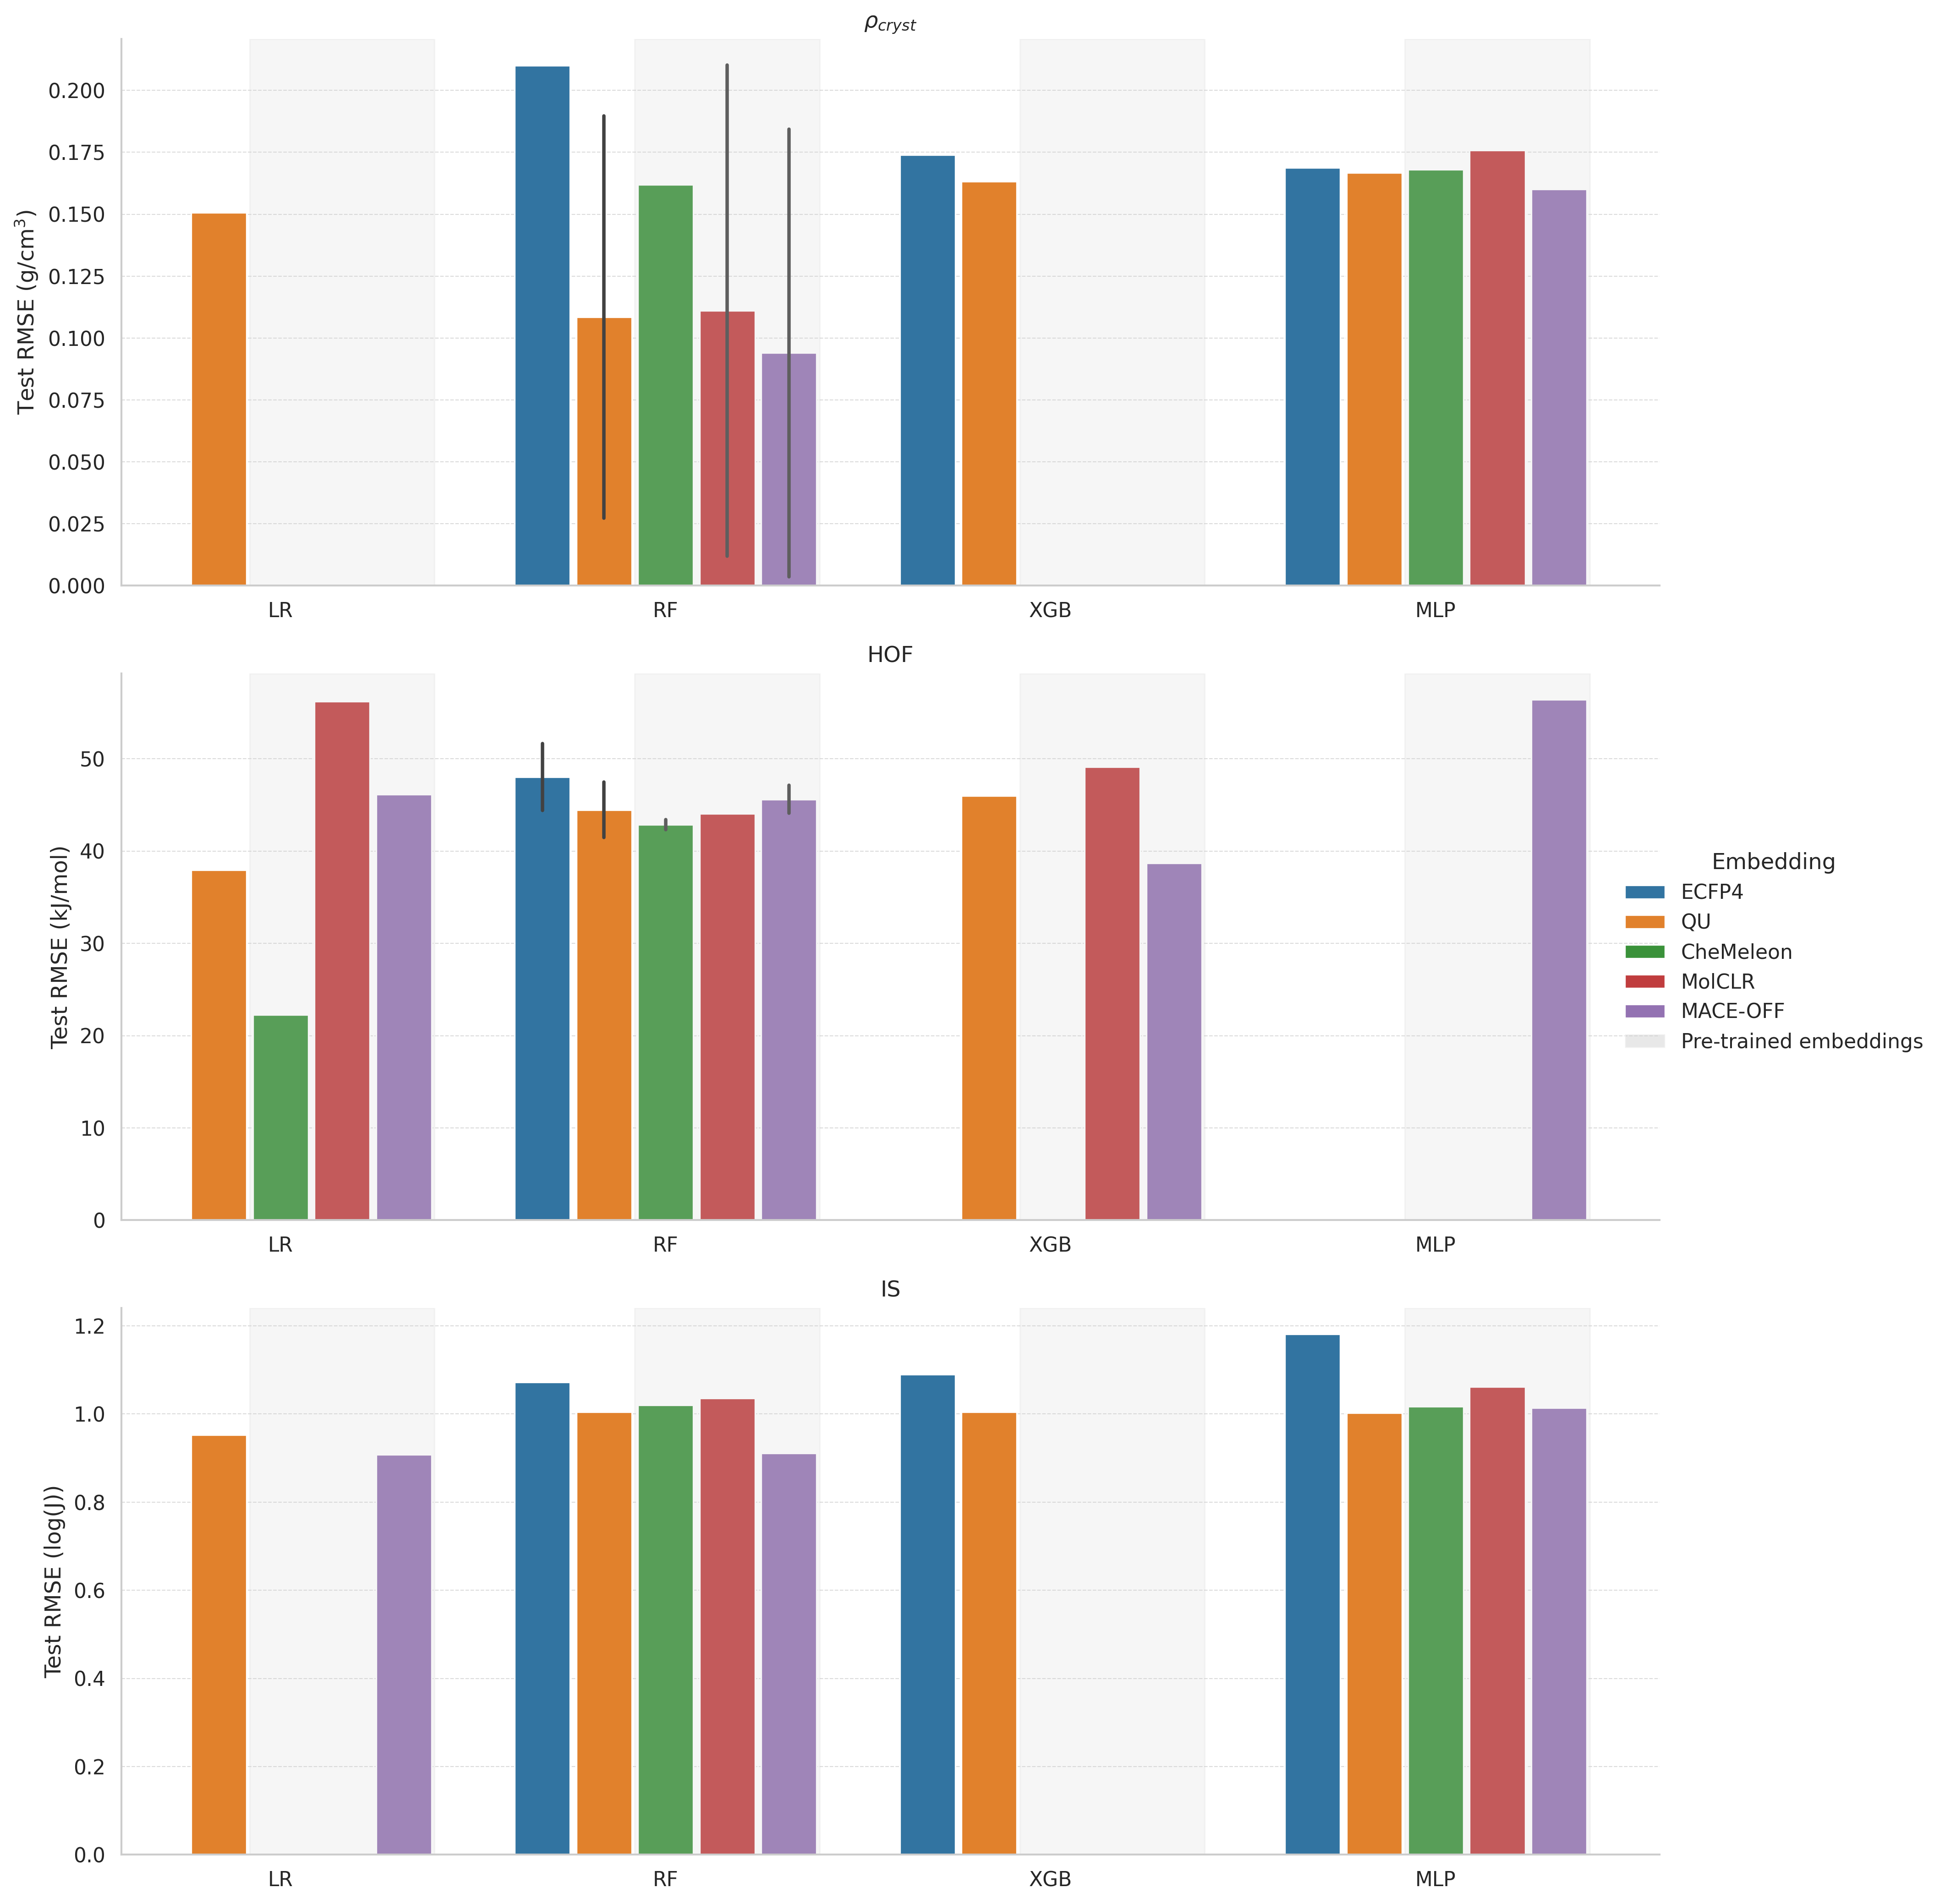

Saved 07_OUTPUTS/20260923/figures/cluster_split_benchmark_rmse.png


In [ ]:
cluster_results = select_split(clean_results, "cluster")
display(summarise_results(cluster_results))
plot_benchmark_rmse(cluster_results, "cluster_split_benchmark_rmse.png");

In [ ]:
cluster_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)

/tmp/ipykernel_50266/1532727472.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)


test_RMSE        test_R2       
                                    mean    std    mean    std
dataset        model embedding                                
$\rho_{cryst}$ LR    ECFP4           NaN    NaN     NaN    NaN
                     QU            0.151    NaN   0.439    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR          NaN    NaN     NaN    NaN
                     MACE-OFF        NaN    NaN     NaN    NaN
               RF    ECFP4         0.210    NaN  -0.091    NaN
                     QU            0.108  0.081   0.455  0.191
                     CheMeleon     0.162    NaN   0.351    NaN
                     MolCLR        0.111  0.099   0.462  0.388
                     MACE-OFF      0.094  0.090   0.620  0.336
               XGB   ECFP4         0.174    NaN   0.251    NaN
                     QU            0.163    NaN   0.341    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR          NaN    NaN     NaN    NaN
                     MACE-OFF        NaN    NaN     NaN    NaN
               MLP   ECFP4         0.169    NaN   0.296    NaN
                     QU            0.167    NaN   0.312    NaN
                     CheMeleon     0.168    NaN   0.301    NaN
                     MolCLR        0.176    NaN   0.235    NaN
                     MACE-OFF      0.160    NaN   0.366    NaN
HOF            LR    ECFP4           NaN    NaN     NaN    NaN
                     QU           37.938    NaN   0.342    NaN
                     CheMeleon    22.254    NaN   0.774    NaN
                     MolCLR       56.215    NaN  -0.444    NaN
                     MACE-OFF     46.138    NaN   0.027    NaN
               RF    ECFP4        48.018  3.634   0.073  0.343
                     QU           44.461  3.012   0.231  0.070
                     CheMeleon    42.861  0.568   0.278  0.144
                     MolCLR       44.052    NaN   0.357    NaN
                     MACE-OFF     45.612  1.502   0.173  0.239
               XGB   ECFP4           NaN    NaN     NaN    NaN
                     QU           45.976    NaN   0.034    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR       49.108    NaN  -0.102    NaN
                     MACE-OFF     38.707    NaN   0.315    NaN
               MLP   ECFP4           NaN    NaN     NaN    NaN
                     QU              NaN    NaN     NaN    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR          NaN    NaN     NaN    NaN
                     MACE-OFF     56.427    NaN  -0.056    NaN
IS             LR    ECFP4           NaN    NaN     NaN    NaN
                     QU            0.952    NaN   0.297    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR          NaN    NaN     NaN    NaN
                     MACE-OFF      0.908    NaN   0.361    NaN
               RF    ECFP4         1.072    NaN   0.109    NaN
                     QU            1.004    NaN   0.218    NaN
                     CheMeleon     1.020    NaN   0.192    NaN
                     MolCLR        1.035    NaN   0.168    NaN
                     MACE-OFF      0.911    NaN   0.357    NaN
               XGB   ECFP4         1.090    NaN   0.079    NaN
                     QU            1.005    NaN   0.217    NaN
                     CheMeleon       NaN    NaN     NaN    NaN
                     MolCLR          NaN    NaN     NaN    NaN
                     MACE-OFF        NaN    NaN     NaN    NaN
               MLP   ECFP4         1.182    NaN  -0.083    NaN
                     QU            1.002    NaN   0.221    NaN
                     CheMeleon     1.017    NaN   0.197    NaN
                     MolCLR        1.062    NaN   0.125    NaN
                     MACE-OFF      1.014    NaN   0.202    NaN

In [ ]:
display(compare_to_best(cluster_results).round(3))
display(rank_embeddings(cluster_results))

ValueError: Need at least two paired runs for dataset='$\\rho_{cryst}$', embedding='CheMeleon'

## Penalty from harder splits

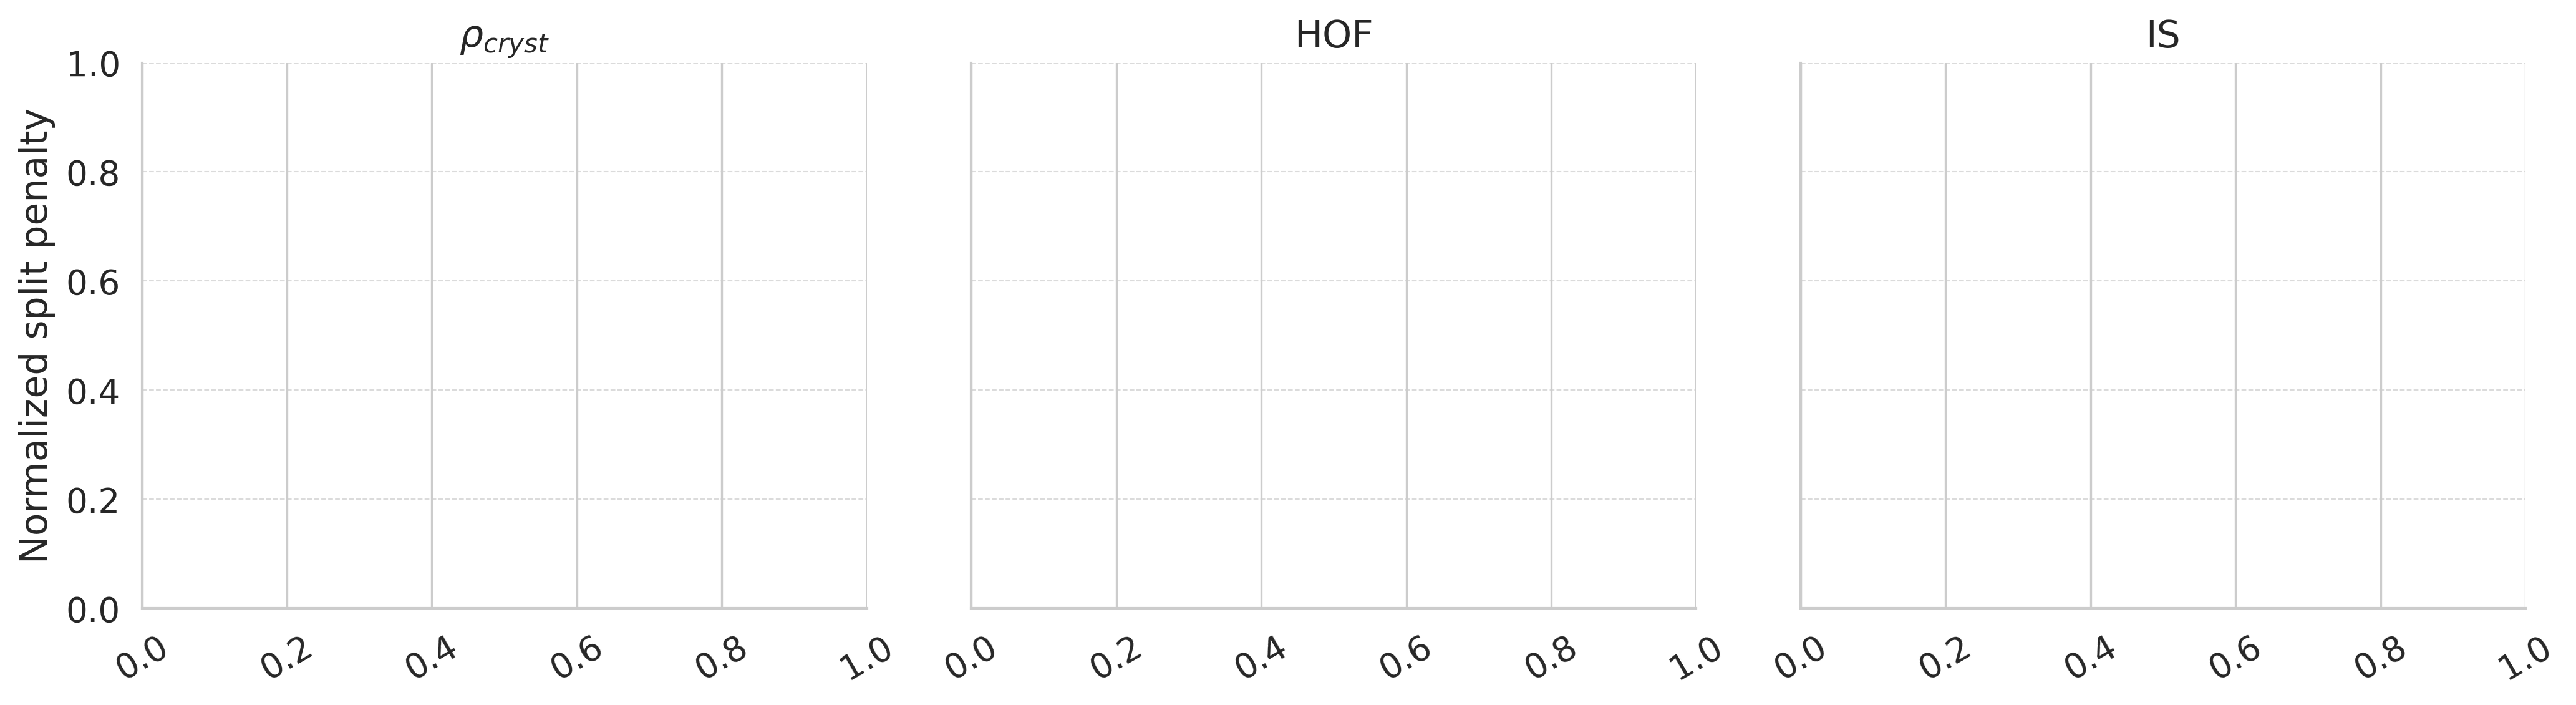

Saved 07_OUTPUTS/20260923/figures/normalized_cluster_split_penalty.png


In [ ]:
def calculate_split_penalties(results: pd.DataFrame) -> pd.DataFrame:
    group_columns = ["dataset", "embedding", "model"]
    random_means = (
        select_split(results, "random_seed")
        .groupby(group_columns, as_index=False, observed=True)["test_RMSE"]
        .mean()
        .rename(columns={"test_RMSE": "random_RMSE"})
    )
    cluster_means = (
        select_split(results, "cluster")
        .groupby(group_columns, as_index=False, observed=True)["test_RMSE"]
        .mean()
        .rename(columns={"test_RMSE": "cluster_RMSE"})
    )
    penalties = random_means.merge(cluster_means, on=group_columns, how="inner")
    penalties["normalized_split_penalty"] = (
        penalties["cluster_RMSE"] - penalties["random_RMSE"]
    ) / penalties["random_RMSE"]
    return penalties


def plot_split_penalties(penalties: pd.DataFrame) -> plt.Figure:
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.5)
    fig, axes = plt.subplots(1, len(DATASET_ORDER), figsize=(14, 4), sharey=True, dpi=300)

    for ax, dataset in zip(np.atleast_1d(axes), DATASET_ORDER):
        subset = penalties.loc[penalties["dataset"] == dataset]
        sns.pointplot(
            data=subset,
            x="embedding",
            y="normalized_split_penalty",
            hue="embedding",
            order=EMBEDDING_ORDER,
            palette=sns.color_palette("tab10", n_colors=len(EMBEDDING_ORDER)),
            errorbar="sd",
            markers="o",
            linestyles="none",
            legend=False,
            ax=ax,
        )
        ax.set(
            title=str(dataset),
            xlabel="",
            ylabel="Normalized split penalty" if ax is axes[0] else "",
        )
        ax.tick_params(axis="x", rotation=30)
        ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
        sns.despine(ax=ax)

    fig.tight_layout()
    save_figure(fig, "normalized_cluster_split_penalty.png")
    return fig


split_penalties = calculate_split_penalties(df)
plot_split_penalties(split_penalties);

In [ ]:
display(
    split_penalties.groupby(["dataset", "embedding"], observed=True)
    [["normalized_split_penalty"]]
    .agg(["mean", "std"])
    .round(3)
)

Empty DataFrame
Columns: [(normalized_split_penalty, mean), (normalized_split_penalty, std)]
Index: []

## Impact of the prediction head

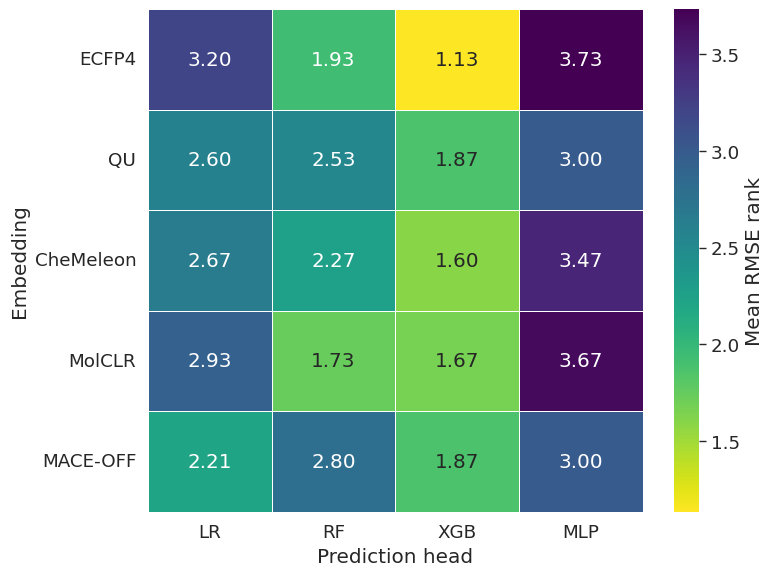

Saved 07_OUTPUTS/20260625/figures/prediction_head_mean_rmse_rank.png


In [ ]:
def plot_prediction_head_ranks(results: pd.DataFrame) -> plt.Figure:
    summary = (
        results.groupby(
            ["dataset", "embedding", "model", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .agg(mean_RMSE="mean")
    )
    summary["rank"] = summary.groupby(
        ["dataset", "embedding", "split_method"], observed=True
    )["mean_RMSE"].rank(method="dense", ascending=True)

    heatmap_data = (
        summary.groupby(["embedding", "model"], observed=True)["rank"]
        .mean()
        .unstack("model")
        .reindex(index=EMBEDDING_ORDER, columns=MODEL_ORDER)
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="viridis_r",
        linewidths=0.5,
        cbar_kws={"label": "Mean RMSE rank"},
        ax=ax,
    )
    ax.set(xlabel="Prediction head", ylabel="Embedding")
    ax.tick_params(axis="both", rotation=0)
    fig.tight_layout()
    save_figure(fig, "prediction_head_mean_rmse_rank.png")
    return fig


plot_prediction_head_ranks(random_results);

## Prediction parity and residuals

In [ ]:
prediction_script = REPO_ROOT / "05_PY_SCRIPTS" / "generate_xgb_predictions.py"
subprocess.run([sys.executable, str(prediction_script)], check=True)

predictions_path = REPO_ROOT / "deep_dive_xgb_predictions.parquet"
predictions_df = pd.read_parquet(predictions_path)
predictions_df["embedding"] = predictions_df["embedding"].replace(EMBEDDING_LABELS)
predictions_df["dataset"] = predictions_df["dataset"].replace(DATASET_LABELS)
predictions_df["dataset"] = pd.Categorical(
    predictions_df["dataset"], categories=DATASET_ORDER, ordered=True
)
predictions_df.head()

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=4/ckpts/hq_descriptor_model=xgboost_seed=4.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
P

,dataset,embedding,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851,1.833033
1,$\rho_{cryst}$,QU,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703,1.706970
2,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828,1.738453
3,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732,1.705867
4,$\rho_{cryst}$,QU,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746,1.755874


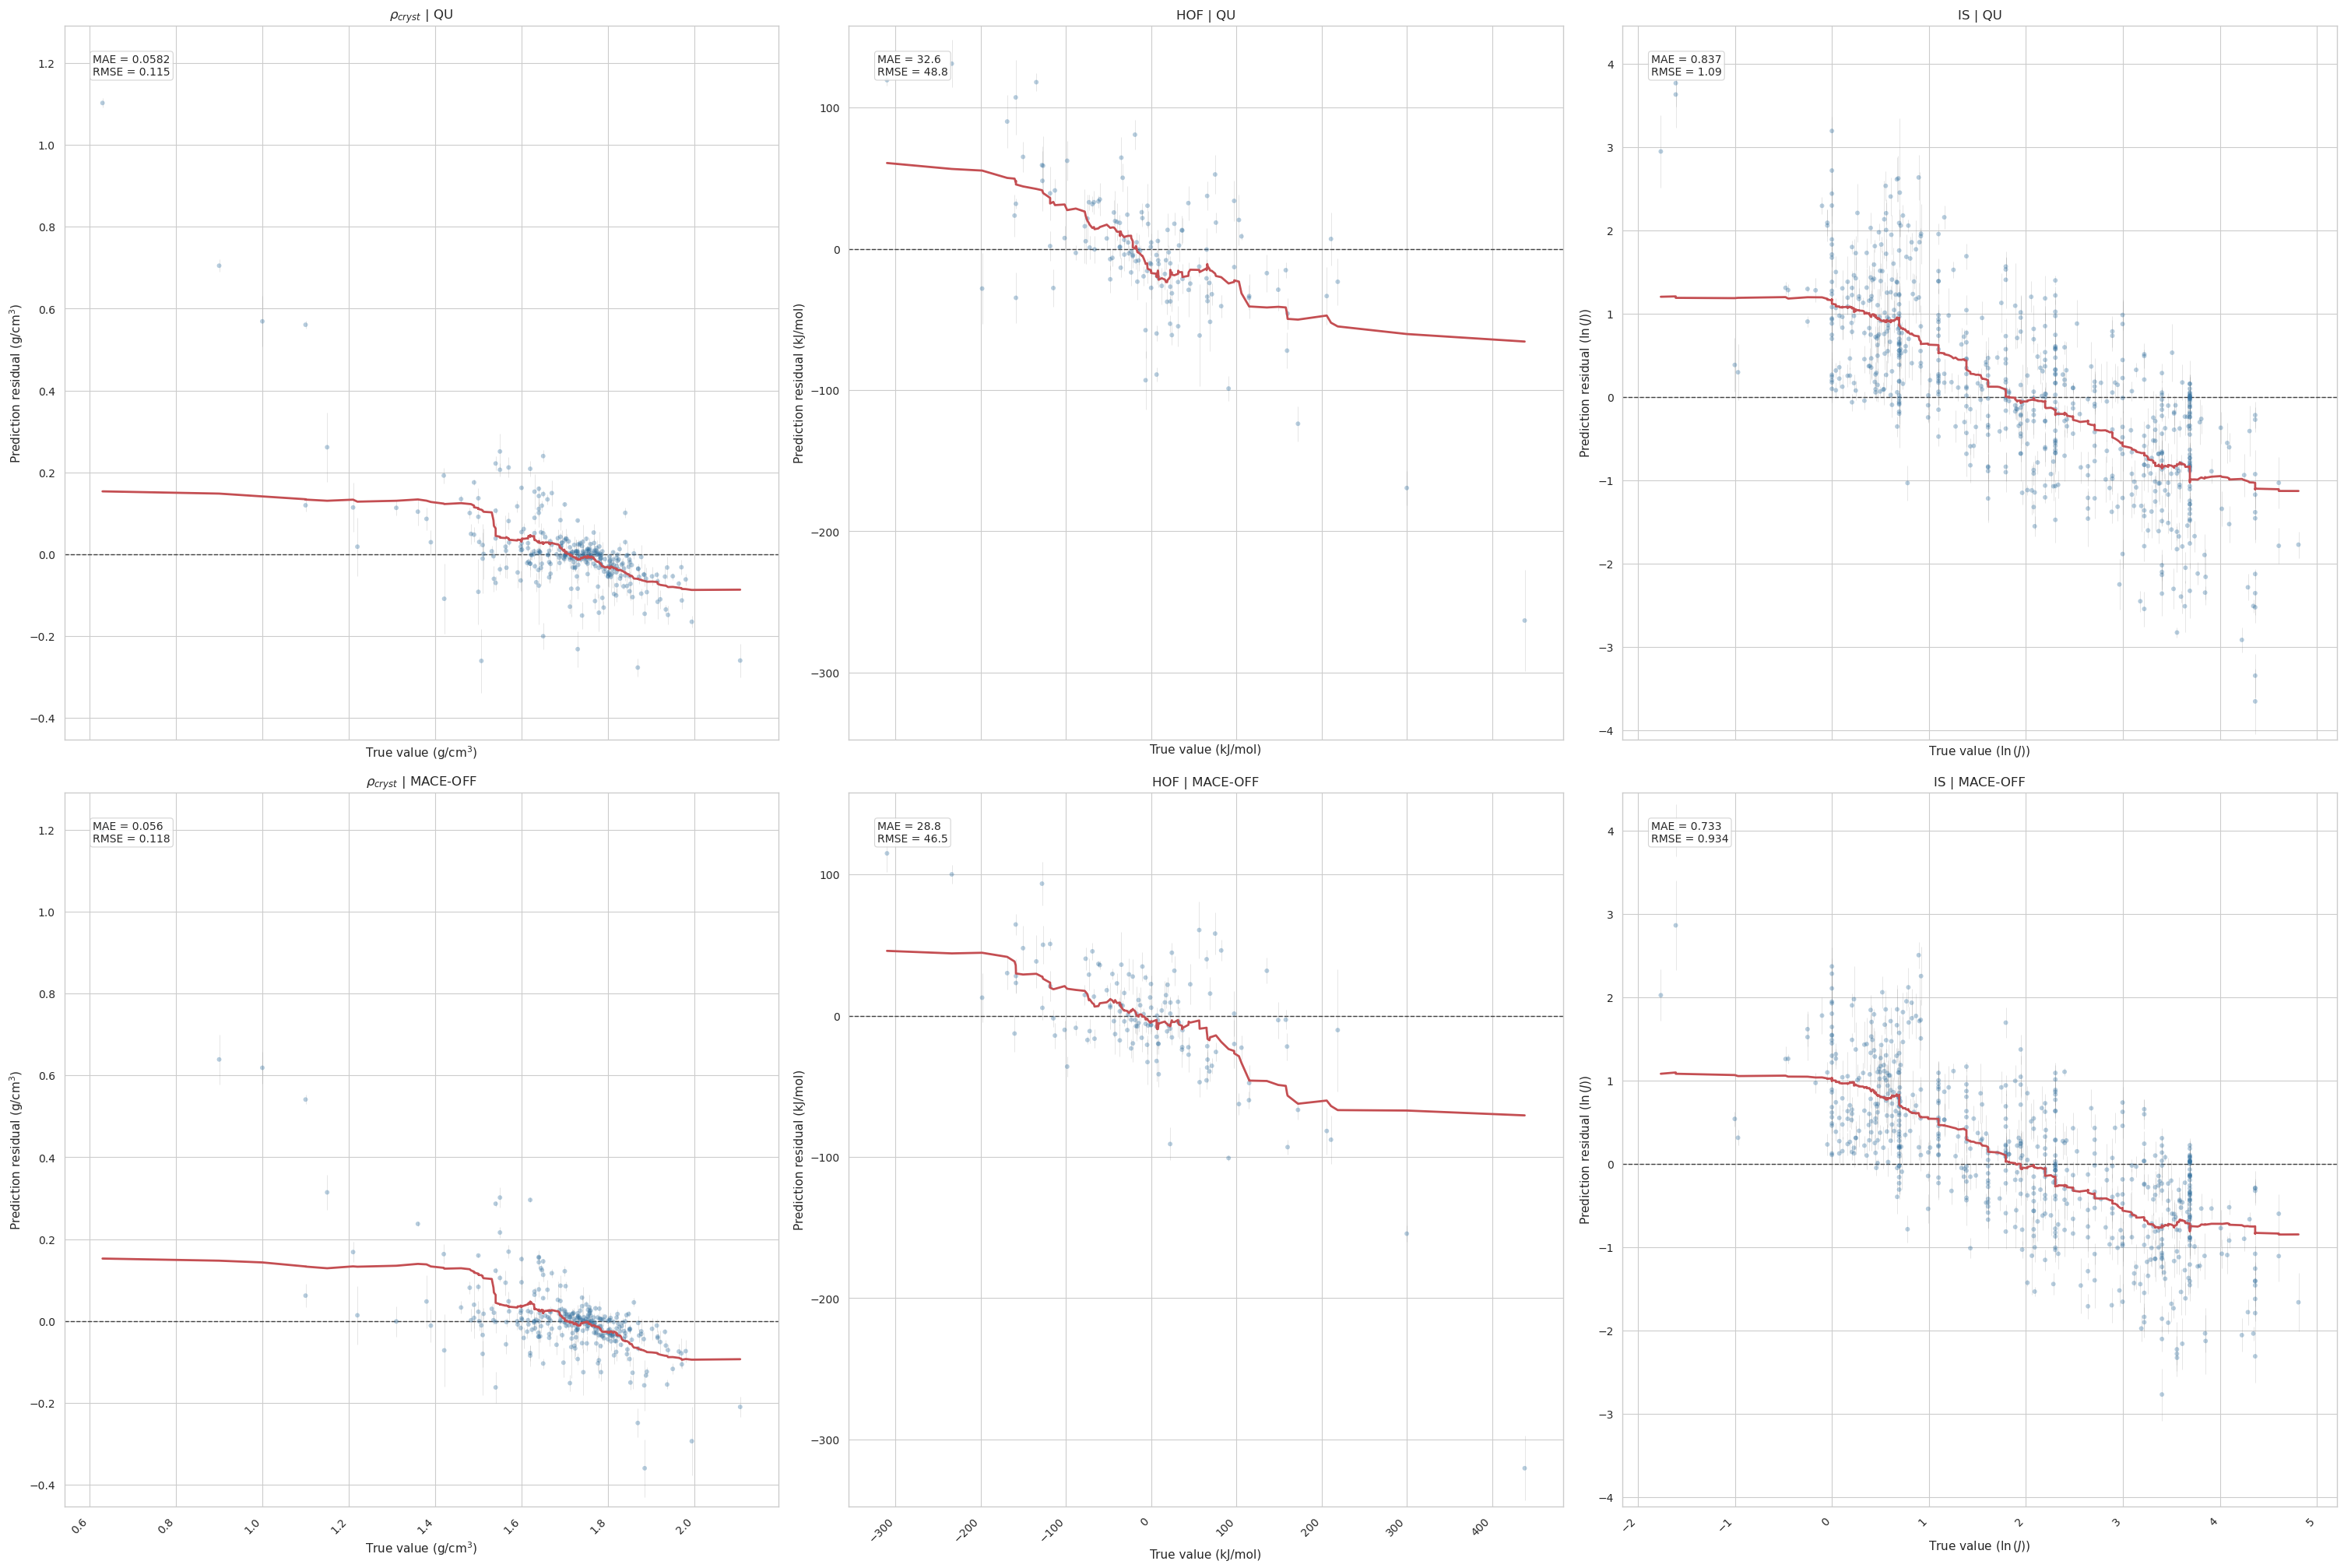

Saved 07_OUTPUTS/20260625/figures/xgb_prediction_residuals.png


In [ ]:
fig = plot_residual_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    show_pred_std=True,
    use_aggregated=True,
    figsize=(30, 20),
)
save_figure(fig, "xgb_prediction_residuals.png");

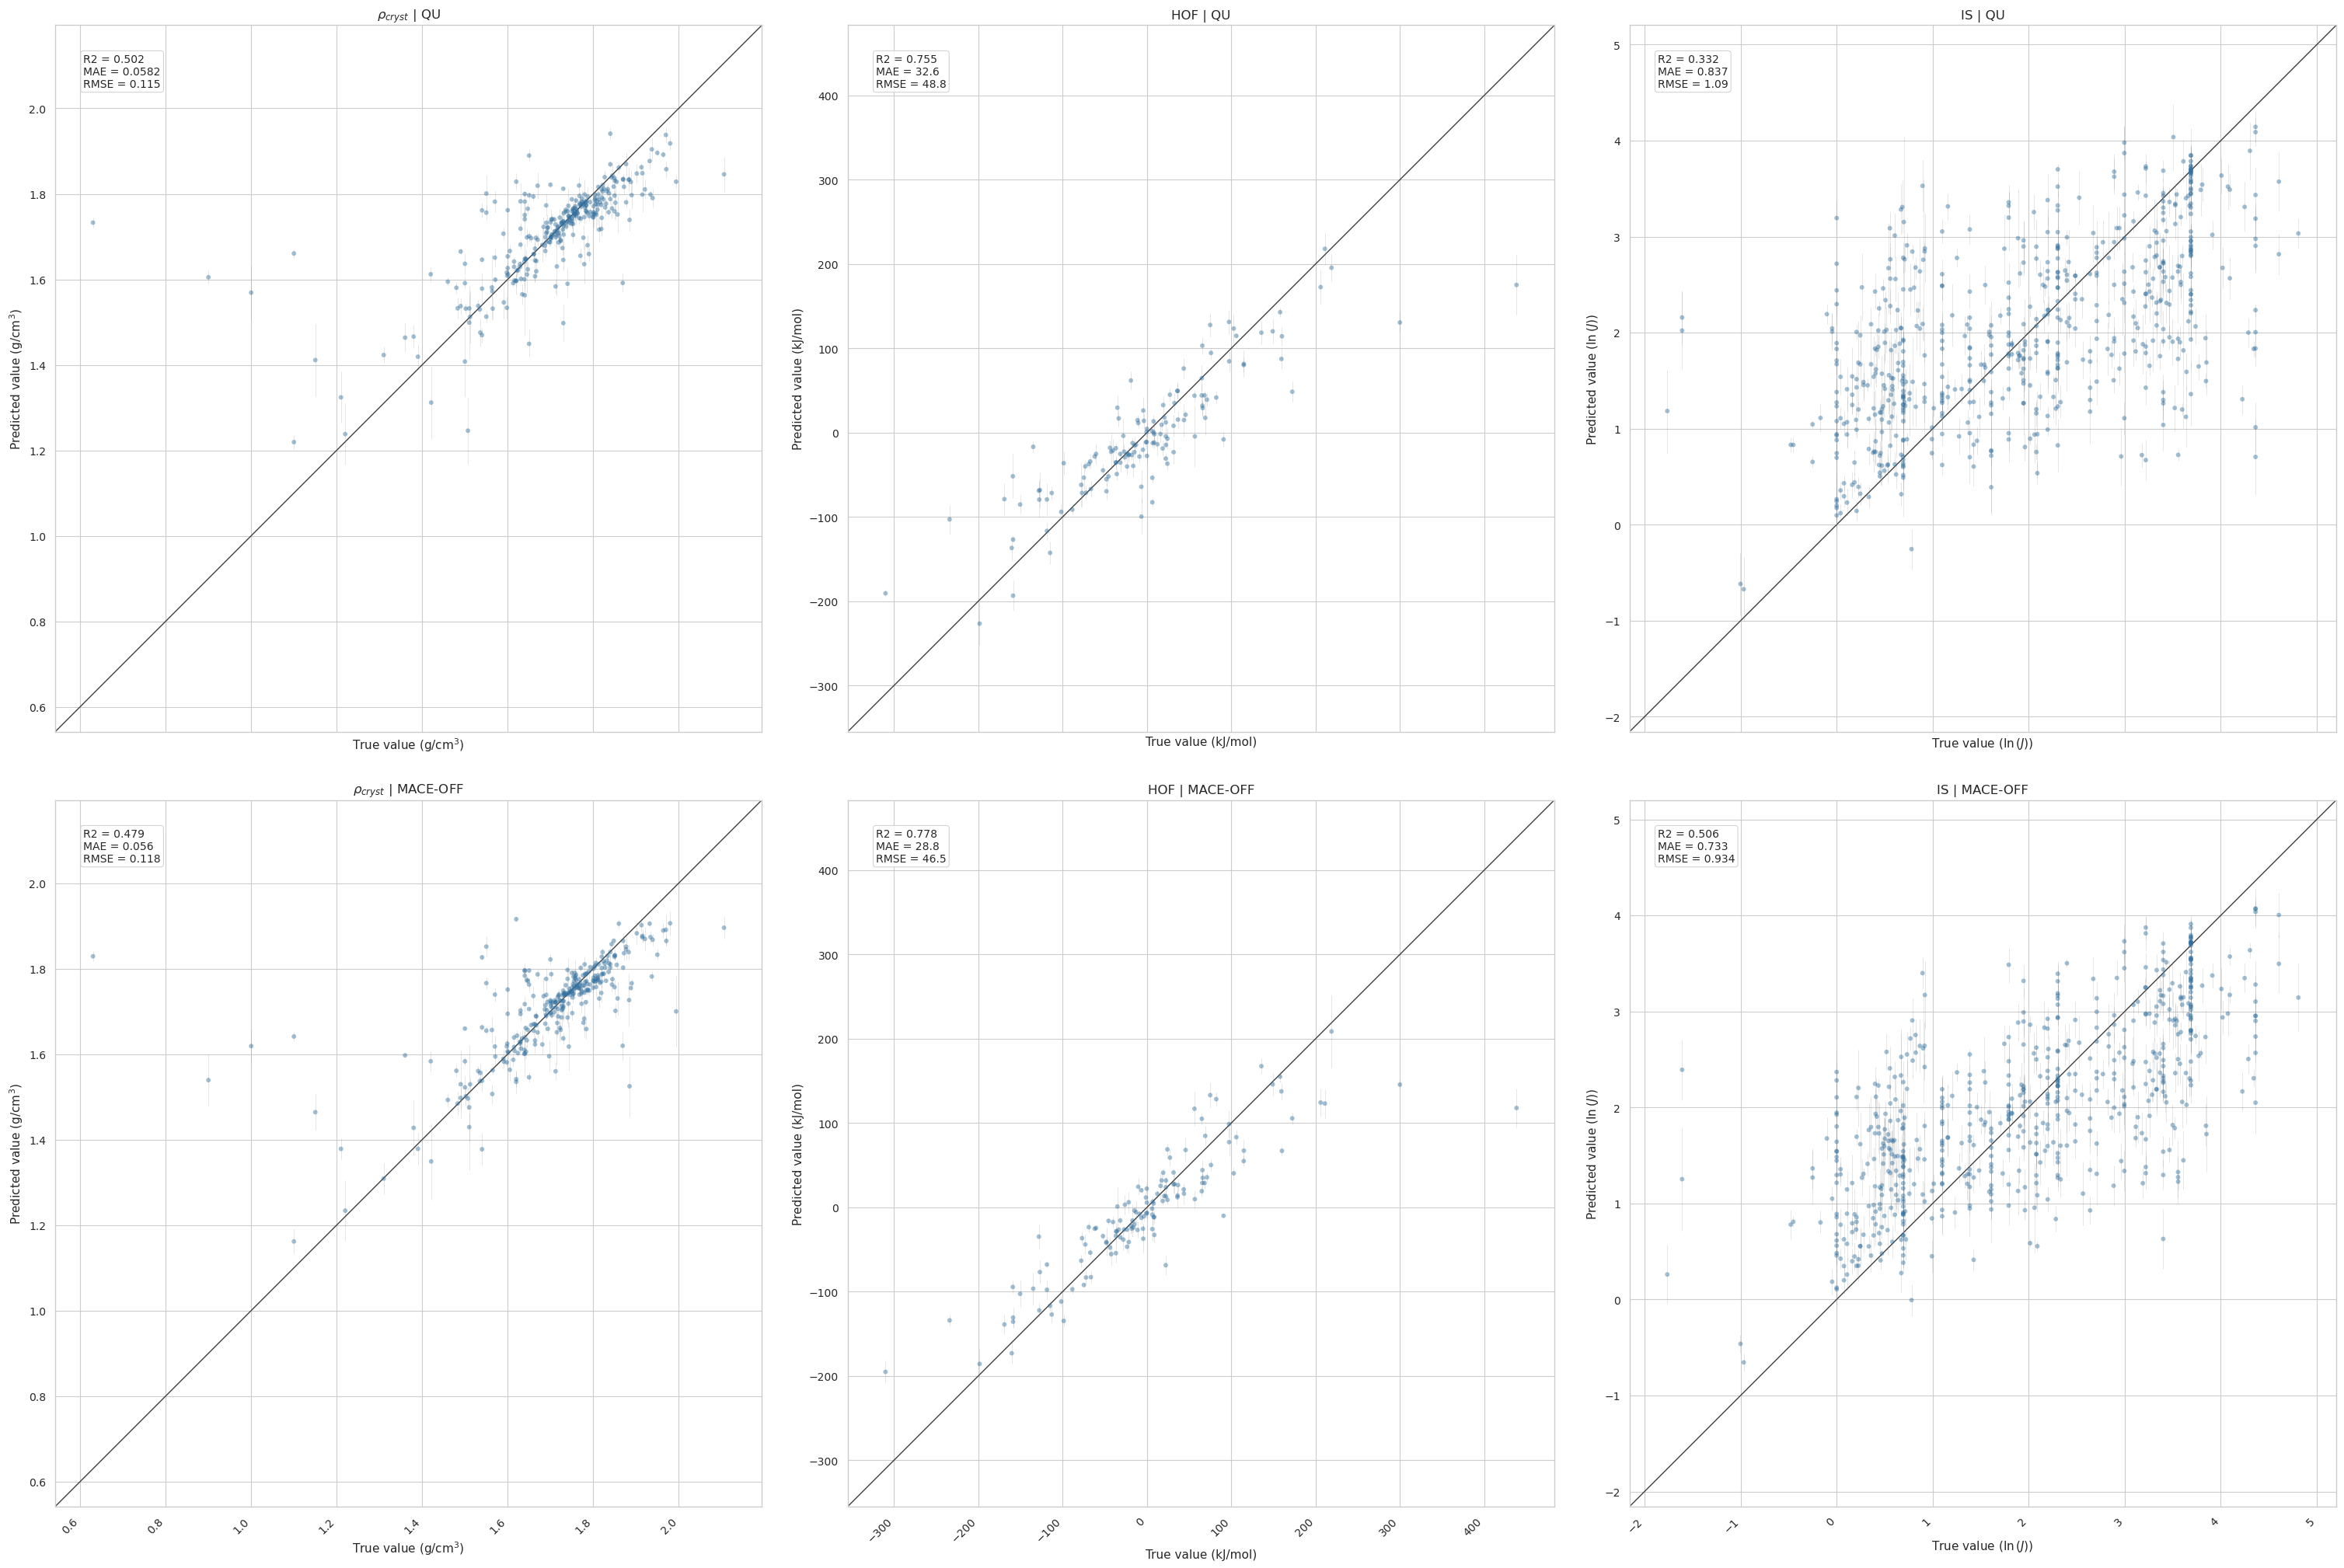

Saved 07_OUTPUTS/20260625/figures/xgb_prediction_parity.png


In [ ]:
fig = plot_parity_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    use_aggregated=True,
    color_by=None,
    show_pred_std=True,
    figsize=(30,20)
)
save_figure(fig, "xgb_prediction_parity.png");